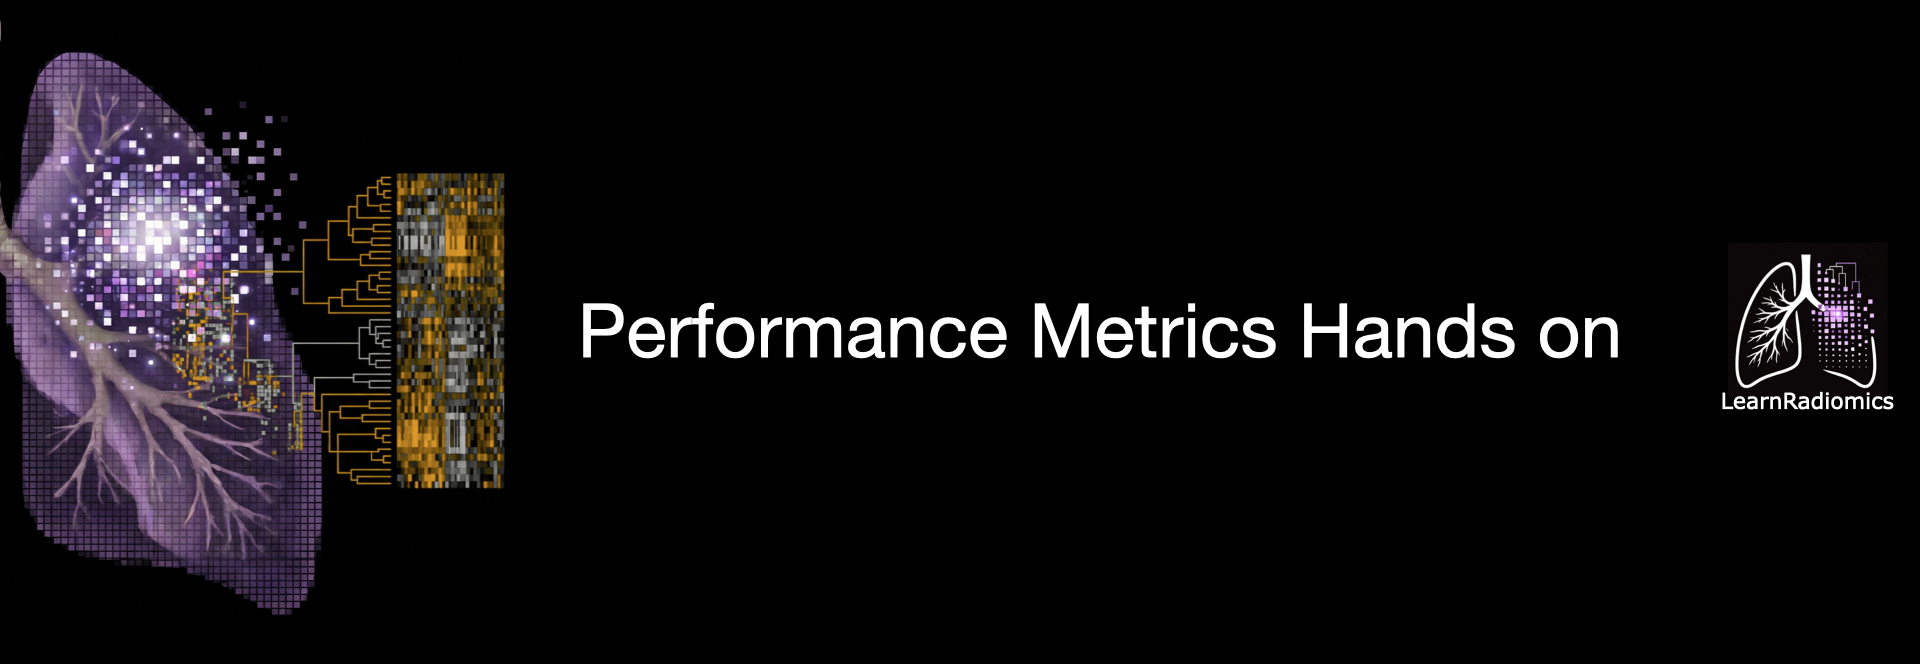

In [ ]:
! pip install SimpleITK

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score)

import warnings
warnings.filterwarnings('ignore')



### Download the course dataset
Run the next cell in Google Colab. The public dataset is downloaded from Cloudflare, checked with SHA-256, and prepared in `/content`. No account or token is required.


In [ ]:
# Public course dataset hosted on Cloudflare (no account or token required).
from pathlib import Path
import hashlib
import time
from urllib.request import Request, urlopen
from urllib.error import URLError
from http.client import HTTPException
import zipfile

DATA_URL = "https://datasets.learnradiomics.com/ia/v1/segmentation_data.zip"
DATA_FILE = Path("/content/segmentation_data.zip")
EXPECTED_SIZE = 4857970
EXPECTED_SHA256 = "2acdb762d66a25d6a50713b29b790cc6db6521b85c9528b38879879e7bcad799"

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
if (DATA_FILE.is_file() and DATA_FILE.stat().st_size == EXPECTED_SIZE
        and file_sha256(DATA_FILE) == EXPECTED_SHA256):
    print(f"Using verified local file: {DATA_FILE.name}")
else:
    # A partial download never replaces the complete file.
    temporary_file = DATA_FILE.with_name(DATA_FILE.name + ".part")
    for attempt in range(1, 4):
        try:
            print(f"Downloading {DATA_FILE.name} ({EXPECTED_SIZE / 1e6:.1f} MB), attempt {attempt}/3...")
            digest = hashlib.sha256()
            downloaded = 0
            request = Request(DATA_URL, headers={"User-Agent": "LearnRadiomics-Course/1.0"})
            with urlopen(request, timeout=60) as response, temporary_file.open("wb") as output:
                for chunk in iter(lambda: response.read(1024 * 1024), b""):
                    output.write(chunk)
                    digest.update(chunk)
                    downloaded += len(chunk)
            if downloaded != EXPECTED_SIZE or digest.hexdigest() != EXPECTED_SHA256:
                raise ValueError("The downloaded file failed its size or SHA-256 check.")
            temporary_file.replace(DATA_FILE)
            break
        except (OSError, URLError, HTTPException, ValueError) as error:
            temporary_file.unlink(missing_ok=True)
            if attempt == 3:
                raise RuntimeError(f"Could not download a verified dataset from {DATA_URL}") from error
            time.sleep(2 * attempt)

# Keep the directory structure used by the exercises; ignore macOS metadata.
with zipfile.ZipFile(DATA_FILE) as archive:
    members = [item for item in archive.infolist()
               if not any(part == "__MACOSX" or part == ".DS_Store" or part.startswith("._")
                          for part in Path(item.filename).parts)]
    for item in members:
        target = (DATA_FILE.parent / item.filename).resolve()
        if not target.is_relative_to(DATA_FILE.parent.resolve()):
            raise ValueError(f"Invalid archive path: {item.filename}")
    archive.extractall(DATA_FILE.parent, members=members)

required_paths = ['segmentation_data/ct_image.nii.gz', 'segmentation_data/ct_segmentation_1.nii.gz', 'segmentation_data/ct_segmentation_2.nii.gz']
for relative_path in required_paths:
    if not (DATA_FILE.parent / relative_path).exists():
        raise FileNotFoundError(f"Missing dataset path: {relative_path}")
print("Dataset ready in /content")


In [ ]:
def show_slice_window(slice, level, window):
    """
    input: imagen array 2D,
    permite ajustar ventana y nivel para mejorar contraste de la imagen.
    output: imagen array 2D ventaneada.
   """
    max = level + window/2
    min = level - window/2
    slice = slice.clip(min,max)
    return(slice)

### Data Structures and Partitioning

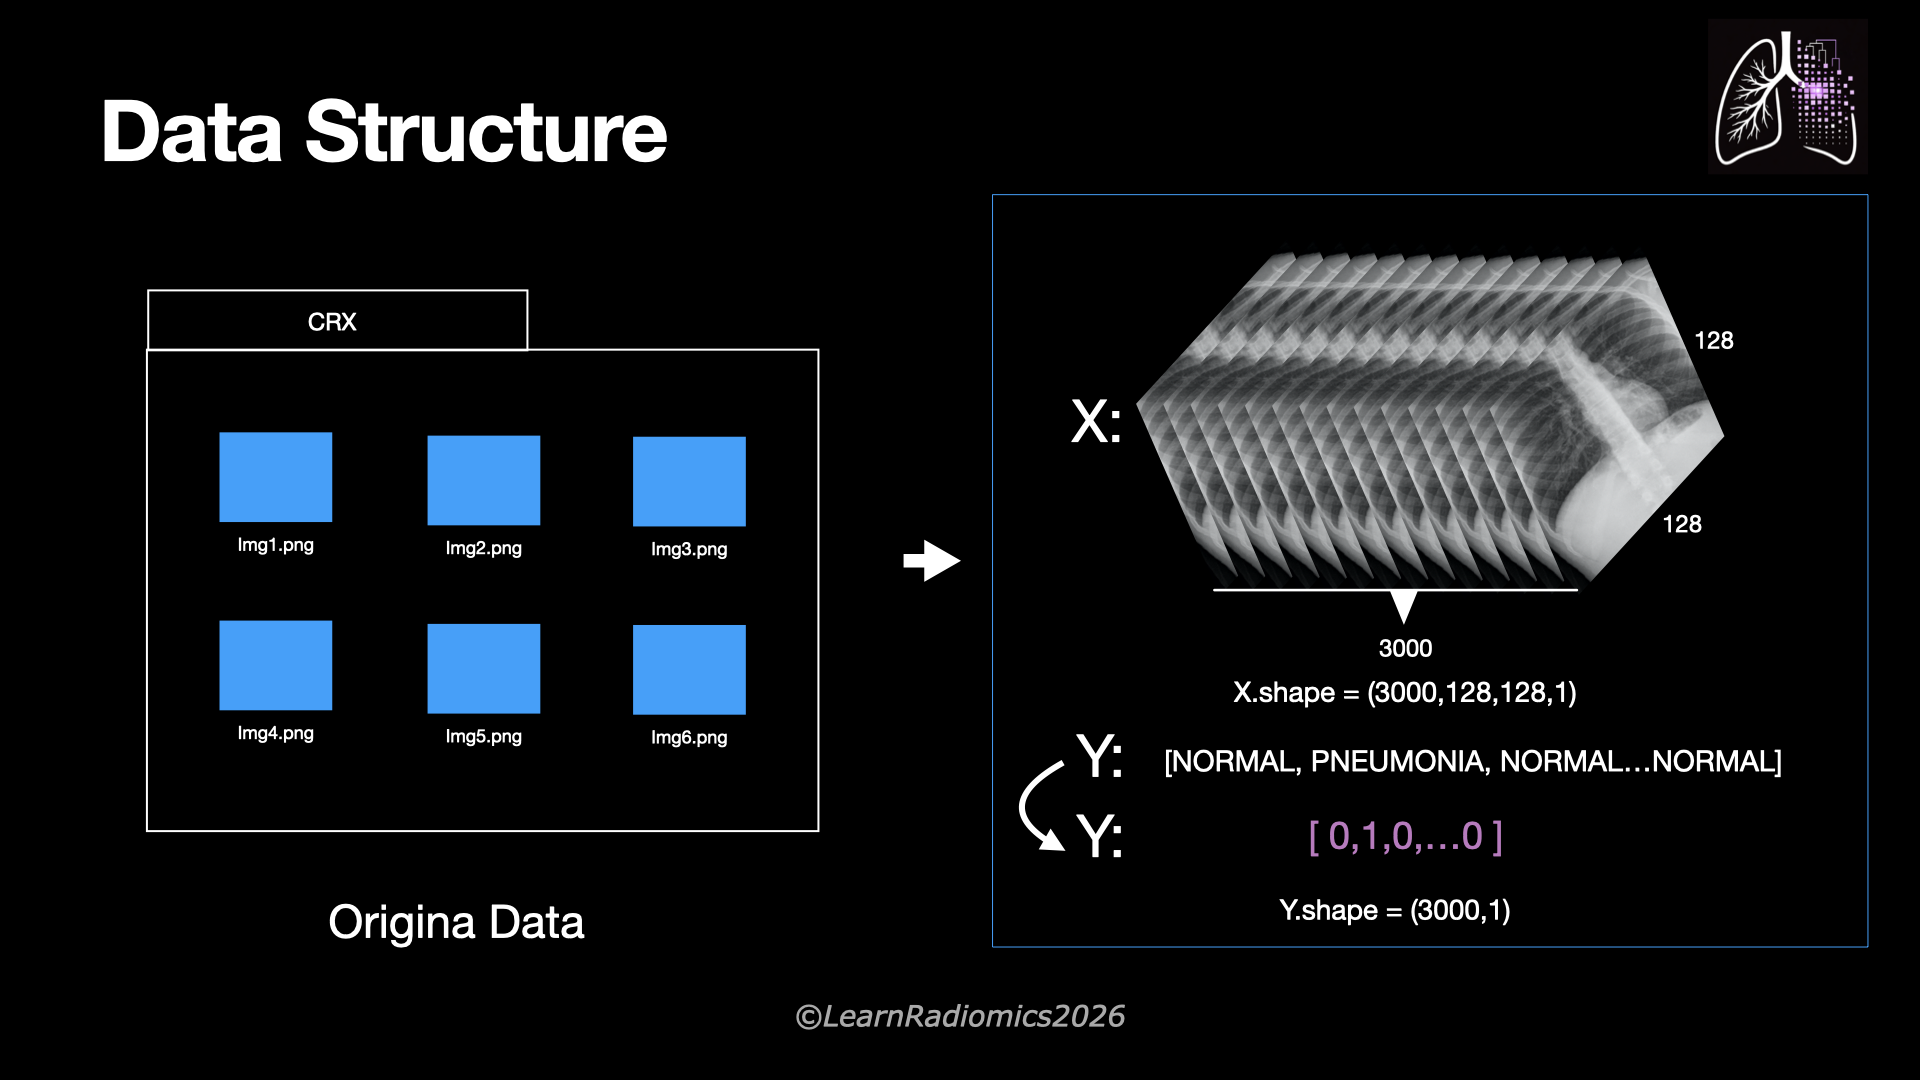

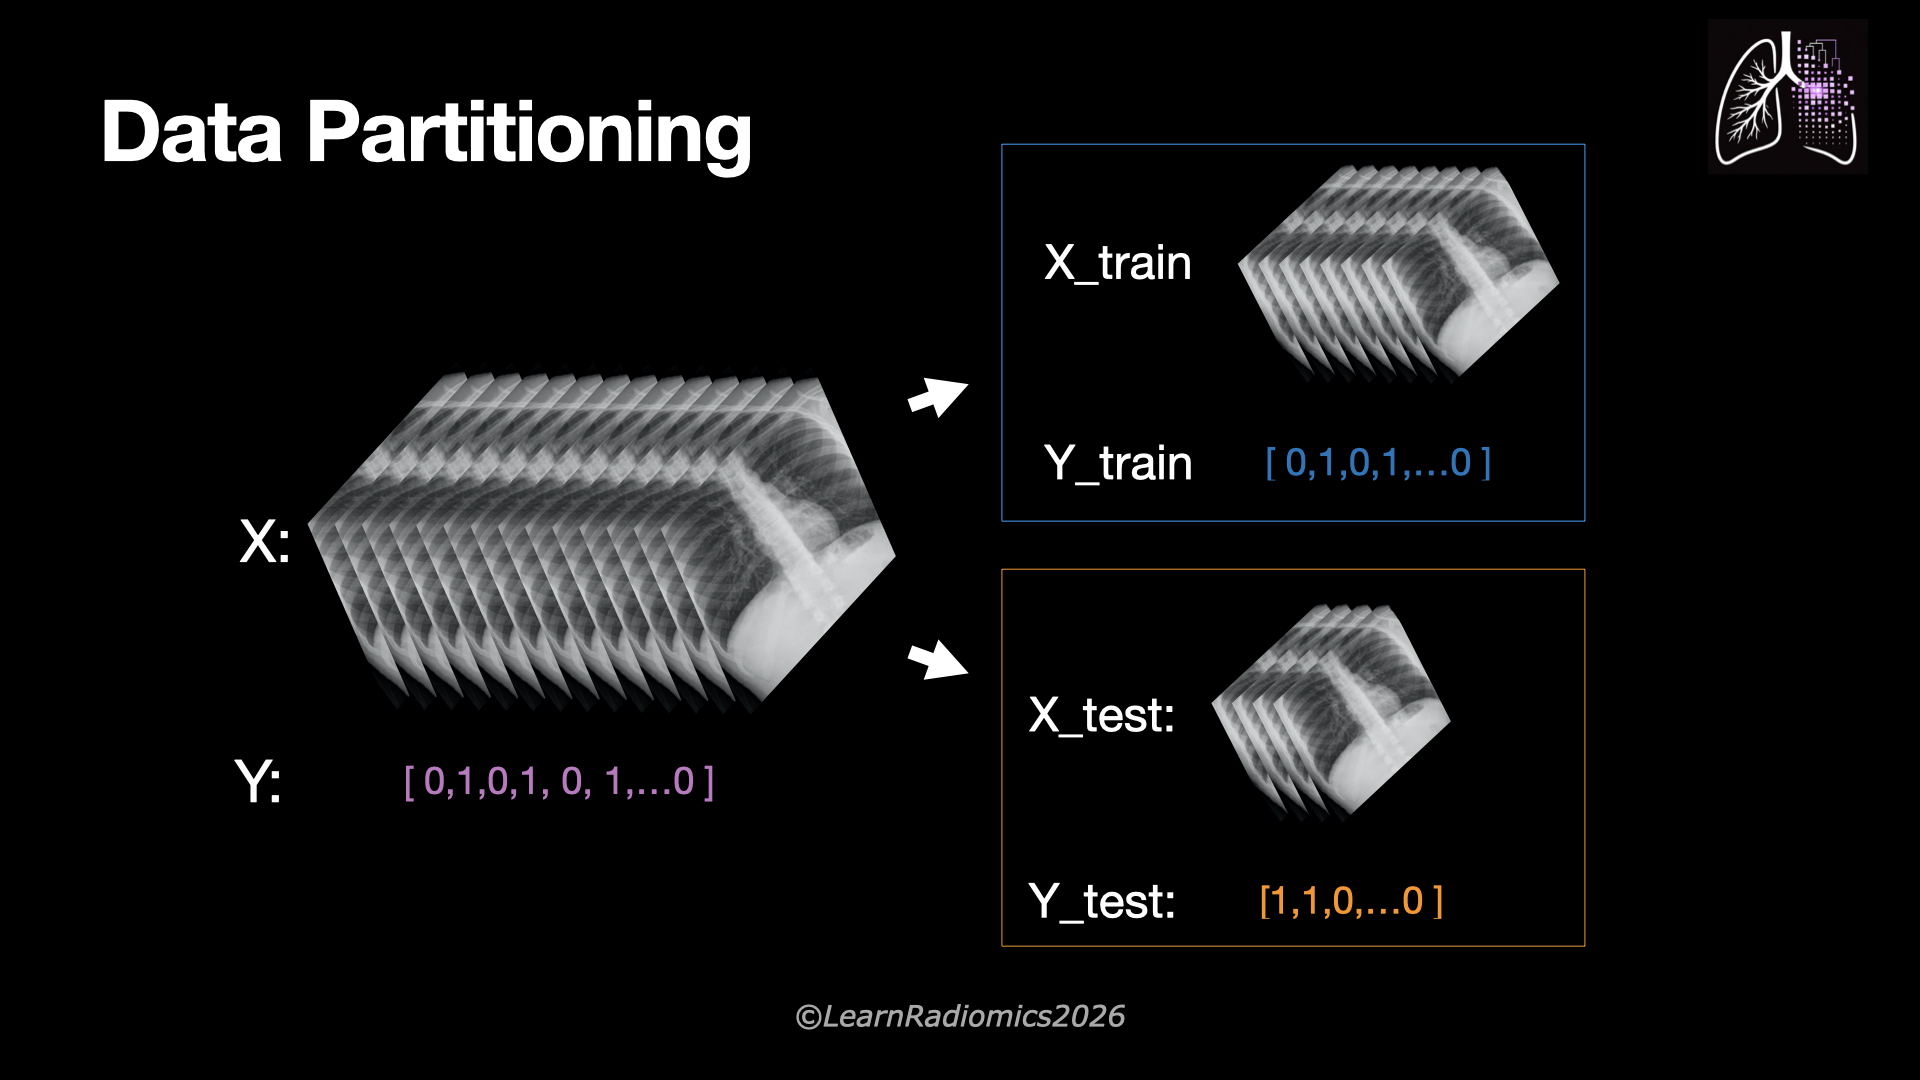

### Binary Classification Taks

In [ ]:
### Simulated dataset for classification task

X_bin, y_bin = make_classification(
    n_samples=1200,
    n_features=10,
    n_informative=5,
    n_redundant=5,
    n_classes=2,
    weights=[0.65, 0.35],
    class_sep=1.2,
    random_state=42)

## Data Partitioning

X_train, X_test, y_train, y_test = train_test_split(
    X_bin,
    y_bin,
    test_size=0.3,
    stratify=y_bin,
    random_state=42)

print("X_train dims:", X_train.shape)
print("y_train dims:", y_train.shape)
print("X_test dims:", X_test.shape)
print("y_test dims:", y_test.shape)

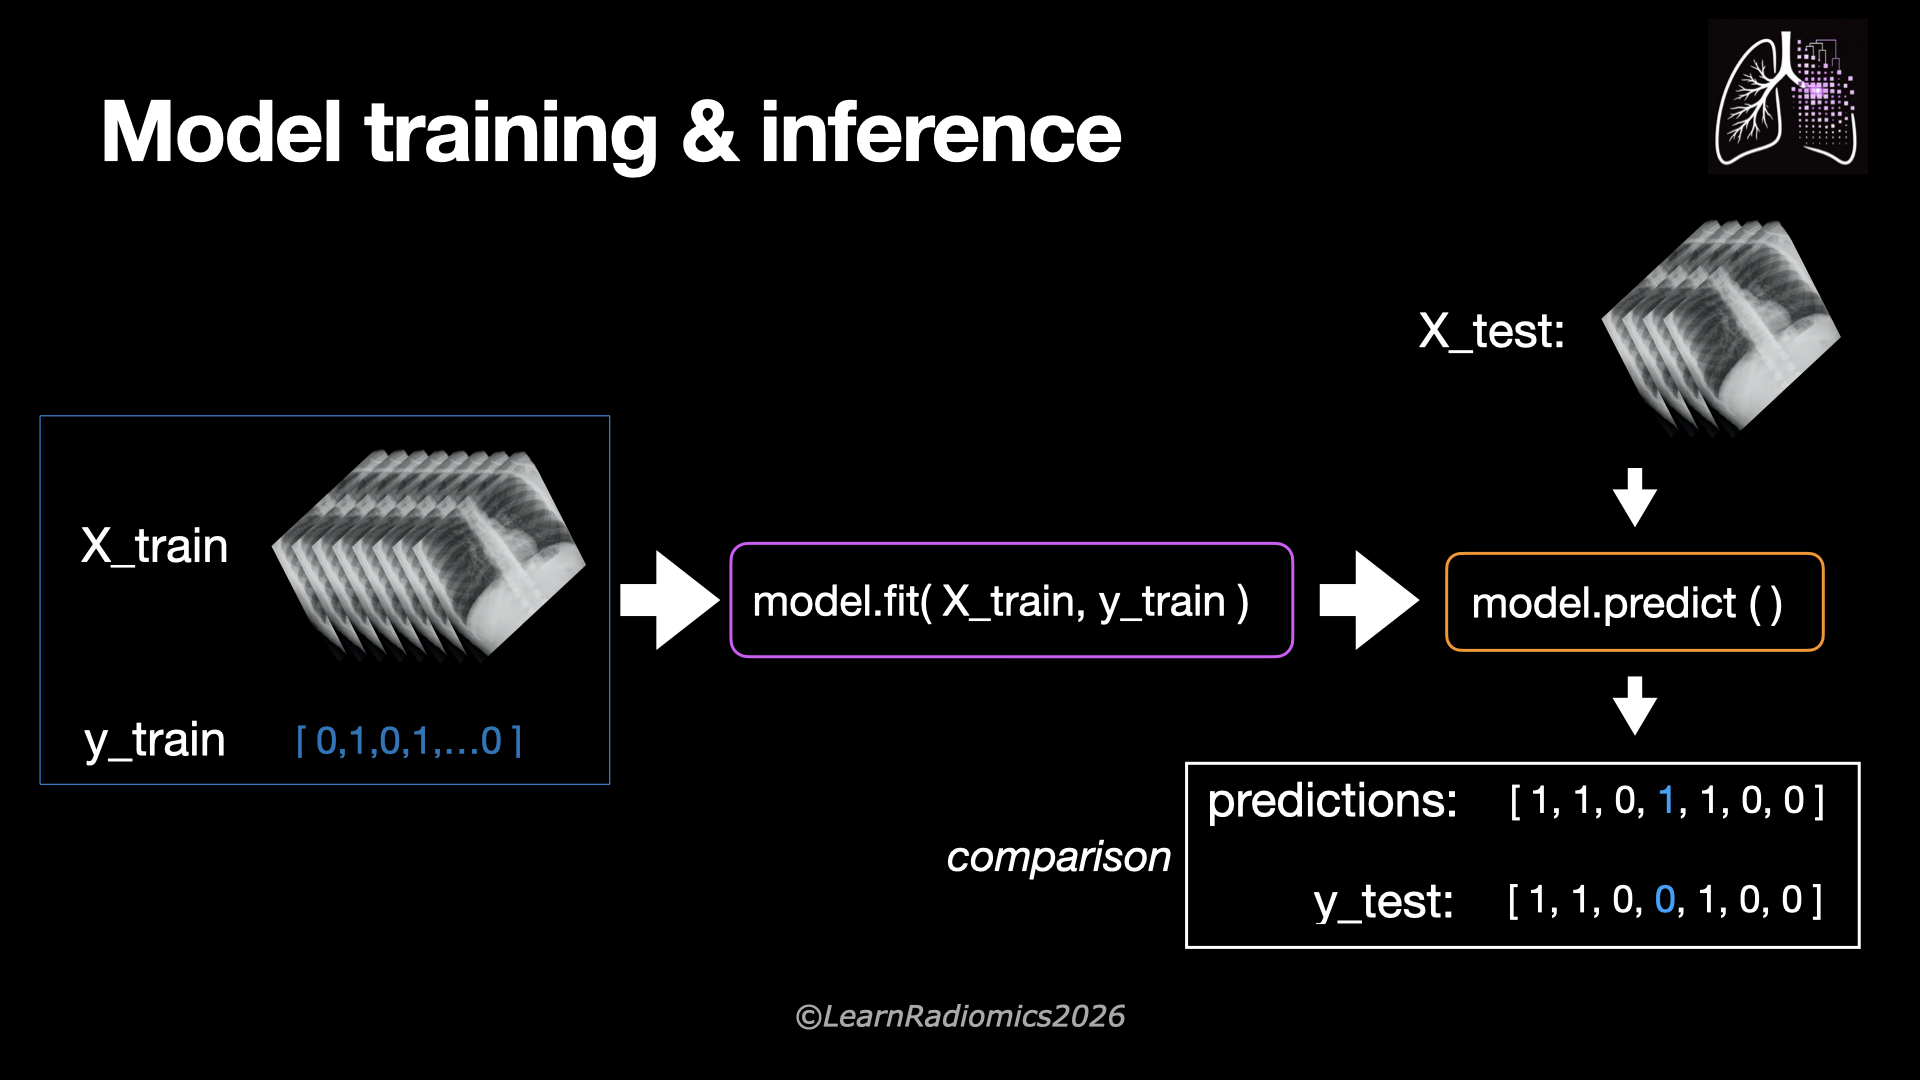

#### Binary Model : Logistic Regression

In [ ]:
binary_model = LogisticRegression(max_iter=1000)

binary_model.fit(X_train, y_train)

y_pred_bin = binary_model.predict(X_test)
y_proba_bin = binary_model.predict_proba(X_test)[:, 1]

print("Predicciones binarias:", y_pred_bin[0:10])
print("*"*90)
print("Probabilidades de clase:", y_proba_bin[0:10])


In [ ]:
## comparación
print("Respuestas  :", y_test[0:10])
print("Predicciones:", y_pred_bin[0:10])

In [ ]:
### confusion matrix

def plot_confusion_matrix(y_true, y_pred, class_names=None, title="Matriz de confusión"):
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, values_format="d")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()



def evaluate_classification_basic(y_true, y_pred, average="binary"):
    print("Classification Report")
    print("=" * 60)
    print(classification_report(y_true, y_pred))

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average=average, zero_division=0),
        "recall": recall_score(y_true, y_pred, average=average, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, average=average, zero_division=0)
    }

    return pd.DataFrame(metrics, index=["value"]).T

In [ ]:
plot_confusion_matrix(
    y_test,
    y_pred_bin,
    class_names=["Normal", "Patológico"],
    title="Matriz de confusión - Clasificación binaria")


In [ ]:
### Classification report

print(classification_report(y_test, y_pred_bin))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_bin).ravel()

print("Predictive Negative Value:", tn / (tn + fn))
print("Predictive Positive Value:", tp / (tp + fp))

In [ ]:
## Threshold adjustment
threshold = 0.08
y_pred_bin = (y_proba_bin >= threshold).astype(int)

plot_confusion_matrix(
    y_test,
    y_pred_bin,
    class_names=["Normal", "Pathologic"],
    title="Confusion Matrix - Threshold Adjustment")

print(classification_report(y_test, y_pred_bin))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_bin).ravel()

print("Predictive Negative Value:", tn / (tn + fn))
print("Predictive Positive Value:", tp / (tp + fp))

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_bin)
roc_auc = auc(fpr, tpr)
print("AUC:", roc_auc)

In [ ]:
### ROC AUC
def plot_binary_roc_curve(y_true, y_score, title="Curva ROC - Clasificación binaria"):
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Azar")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return roc_auc


def plot_binary_precision_recall_curve(y_true, y_score, title="Curva Precision-Recall"):
    precision, recall, thresholds = precision_recall_curve(y_true, y_score)
    avg_precision = average_precision_score(y_true, y_score)

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"Average Precision = {avg_precision:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return avg_precision

In [ ]:
roc_auc_bin = roc_auc_score(y_test, y_proba_bin)
print(f"\nROC AUC binario: {roc_auc_bin:.3f}")

plot_binary_roc_curve(
    y_test,
    y_proba_bin,
    title="Curva ROC - Clasificación binaria"
)

plot_binary_precision_recall_curve(
    y_test,
    y_proba_bin,
    title="Curva Precision-Recall - Clasificación binaria"
)

#### Binary Classification: Imbalance data

In [ ]:
### Binary classification: Imbalance Dataset

class_one_prevalence = 0.05
class_cero_prevalence = 1 - class_one_prevalence


X_bin_imb, y_bin_imb = make_classification(
    n_samples=1200,
    n_features=10,
    n_informative=5,
    n_redundant=5,
    n_classes=2,
    weights=[class_cero_prevalence, class_one_prevalence],
    class_sep=1.2,
    random_state=42)

## Data Partitioning

X_train_imb, X_test_imb, y_train_imb, y_test_imb = train_test_split(
    X_bin_imb,
    y_bin_imb,
    test_size=0.3,
    stratify=y_bin,
    random_state=42)

binary_model = LogisticRegression(max_iter=1000)

binary_model.fit(X_train_imb, y_train_imb)

y_pred_bin_imb = binary_model.predict(X_test_imb)
y_proba_bin_imb = binary_model.predict_proba(X_test_imb)[:, 1]

plot_confusion_matrix(
    y_test_imb,
    y_pred_bin_imb,
    class_names=["Normal", "Pathologic"],
    title="Confusion Matrix - Imbalance Dataset")


print(classification_report(y_test_imb, y_pred_bin_imb))
tn, fp, fn, tp = confusion_matrix(y_test_imb, y_pred_bin_imb).ravel()

print("Predictive Negative Value:", tn / (tn + fn))
print("Predictive Positive Value:", tp / (tp + fp))

roc_auc_bin = roc_auc_score(y_test_imb, y_proba_bin_imb)
print(f"\nROC AUC binario: {roc_auc_bin:.3f}")

plot_binary_roc_curve(
    y_test_imb,
    y_proba_bin_imb,
    title="Curva ROC - Clasificación binaria"
)

plot_binary_precision_recall_curve(
    y_test_imb,
    y_proba_bin_imb,
    title="Curva Precision-Recall - Clasificación binaria"
)


### Multiclass Classification

In [ ]:
print("\n" + "#" * 80)
print("CLASIFICACIÓN MULTICLASE")
print("#" * 80)

X_multi, y_multi = make_classification(
    n_samples=1500,
    n_features=25,
    n_informative=15,
    n_redundant=5,
    n_classes=4,
    n_clusters_per_class=1,
    weights=[0.4, 0.3, 0.2, 0.1],
    class_sep=1.5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X_multi,
    y_multi,
    test_size=0.3,
    stratify=y_multi,
    random_state=42
)

class_names_multi = ["Clase 0", "Clase 1", "Clase 2", "Clase 3"]

multi_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

multi_model.fit(X_train, y_train)

y_pred_multi = multi_model.predict(X_test)
y_proba_multi = multi_model.predict_proba(X_test)

plot_confusion_matrix(
    y_test,
    y_pred_multi,
    class_names=class_names_multi,
    title="Matriz de confusión - Clasificación multiclase"
)



In [ ]:
### Classification metrics
print(classification_report(y_test, y_pred_multi))



In [ ]:
def plot_multiclass_roc_curves(y_true, y_proba, class_names=None):
    """
    Calcula curvas ROC One-vs-Rest para clasificación multiclase.
    """

    classes = np.unique(y_true)
    n_classes = len(classes)

    y_true_bin = label_binarize(y_true, classes=classes)

    plt.figure(figsize=(7, 6))

    aucs = {}

    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)

        label = class_names[i] if class_names is not None else f"Clase {i}"
        plt.plot(fpr, tpr, label=f"{label} | AUC = {roc_auc:.3f}")

        aucs[label] = roc_auc

    plt.plot([0, 1], [0, 1], linestyle="--", label="Azar")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Curvas ROC multiclase - One-vs-Rest")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame.from_dict(aucs, orient="index", columns=["ROC AUC"])


def plot_multiclass_precision_recall_curves(y_true, y_proba, class_names=None):
    """
    Calcula curvas Precision-Recall One-vs-Rest para clasificación multiclase.
    """

    classes = np.unique(y_true)
    n_classes = len(classes)

    y_true_bin = label_binarize(y_true, classes=classes)

    plt.figure(figsize=(7, 6))

    avg_precisions = {}

    for i in range(n_classes):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_proba[:, i])
        avg_precision = average_precision_score(y_true_bin[:, i], y_proba[:, i])

        label = class_names[i] if class_names is not None else f"Clase {i}"
        plt.plot(recall, precision, label=f"{label} | AP = {avg_precision:.3f}")

        avg_precisions[label] = avg_precision

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Curvas Precision-Recall multiclase - One-vs-Rest")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame.from_dict(
        avg_precisions,
        orient="index",
        columns=["Average Precision"]
    )


In [ ]:
roc_auc_multi_macro = roc_auc_score(
    y_test,
    y_proba_multi,
    multi_class="ovr",
    average="macro"
)

roc_auc_multi_weighted = roc_auc_score(
    y_test,
    y_proba_multi,
    multi_class="ovr",
    average="weighted"
)

print(f"\nROC AUC multiclase macro: {roc_auc_multi_macro:.3f}")
print(f"ROC AUC multiclase weighted: {roc_auc_multi_weighted:.3f}")

multiclass_auc_table = plot_multiclass_roc_curves(
    y_test,
    y_proba_multi,
    class_names=class_names_multi
)

print("\nROC AUC por clase")
print(multiclass_auc_table)

multiclass_pr_table = plot_multiclass_precision_recall_curves(
    y_test,
    y_proba_multi,
    class_names=class_names_multi
)

print("\nAverage Precision por clase")
print(multiclass_pr_table)

## Segmentation Metrics


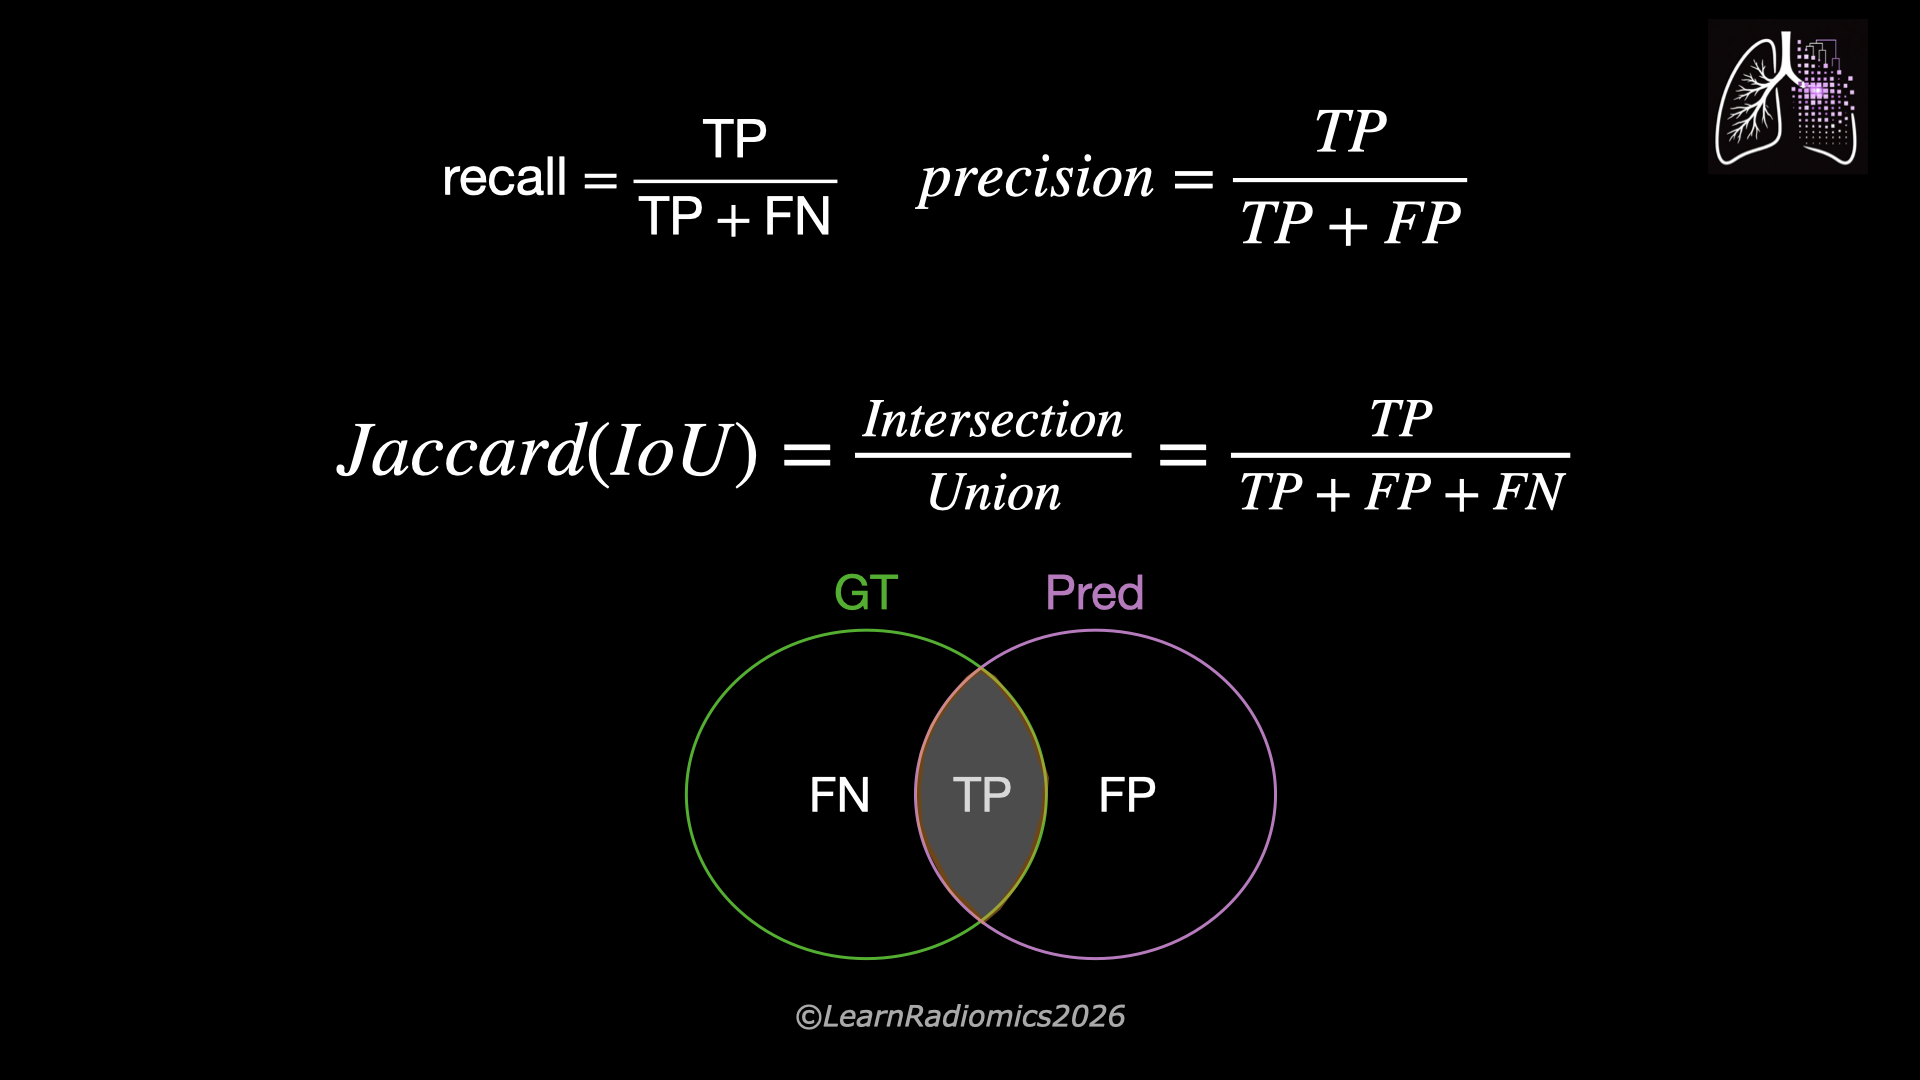

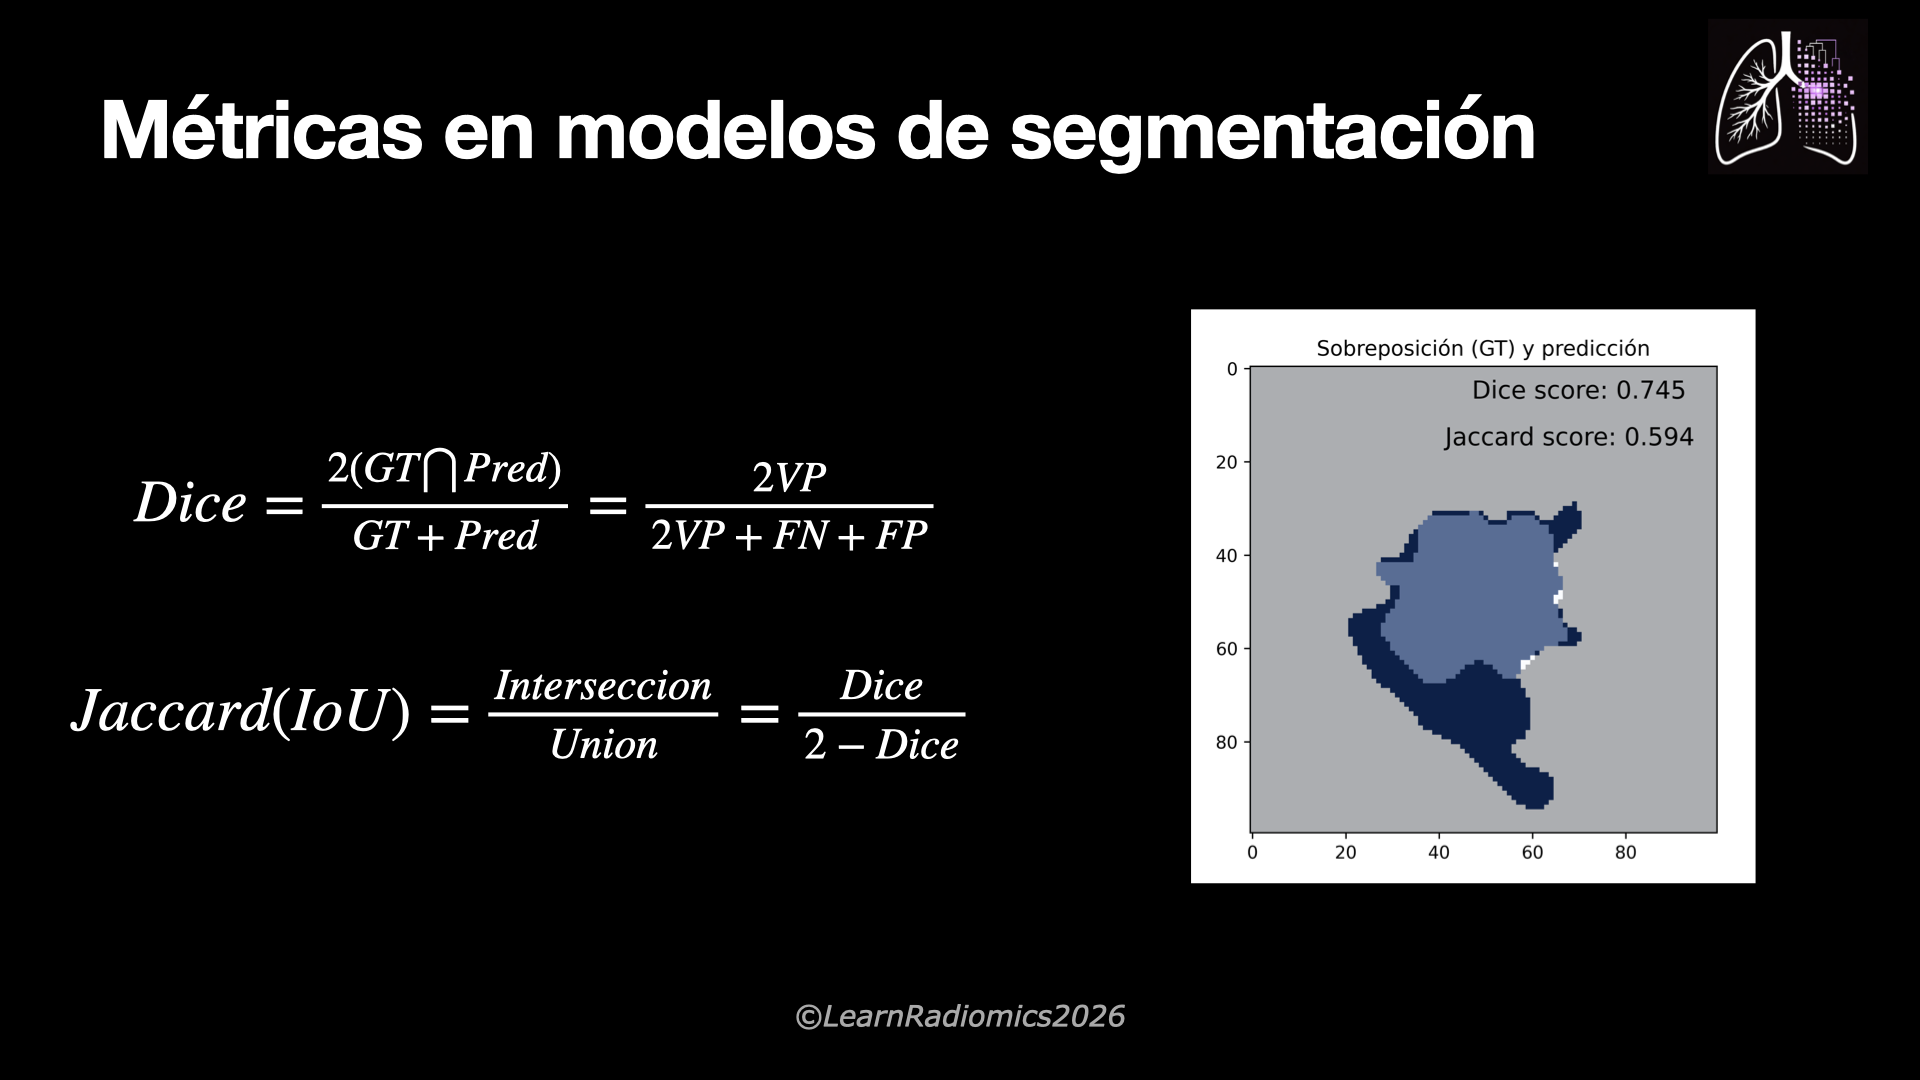

#### Loading Imagen and segmentation masks

In [ ]:
## load segmentation masks

image = sitk.ReadImage("/content/segmentation_data/ct_image.nii.gz")
mask_pred =  sitk.ReadImage("/content/segmentation_data/ct_segmentation_1.nii.gz")
mask_GT =  sitk.ReadImage("/content/segmentation_data/ct_segmentation_2.nii.gz")

image_array = sitk.GetArrayFromImage(image)
pred_mask_array = sitk.GetArrayFromImage(mask_pred)
gt_mask_array = sitk.GetArrayFromImage(mask_GT)
print(image_array.shape)
print(pred_mask_array.shape)
print(gt_mask_array.shape)

In [ ]:
n_slice = 10

plt.figure()
plt.imshow(show_slice_window(image_array[n_slice,200:300,90:190],200, 800), cmap='gray')
plt.imshow(gt_mask_array[n_slice,200:300,90:190], cmap='Blues', alpha=0.4)
plt.imshow(pred_mask_array[n_slice,200:300,90:190], cmap='Blues_r', alpha=0.5)
plt.show()

In [ ]:
gt_slice = gt_mask_array[n_slice,200:300,90:190]
pred_slice = pred_mask_array[n_slice,200:300,90:190]

tn, fp, fn, tp = confusion_matrix(gt_slice.ravel(), pred_slice.ravel()).ravel()

print(classification_report(gt_slice.ravel(), pred_slice.ravel()))

IoU = tp/(tp + fp + fn)
print("Intersection Over Union:", IoU)

In [ ]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    # Flatten images to 1D arrays
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()

    # Calculate intersection and union
    intersection = np.sum(y_true_f * y_pred_f)
    score = (2. * intersection + smooth) / (np.sum(y_true_f) + np.sum(y_pred_f) + smooth)
    return score

In [ ]:
print("Dice Score:", dice_coefficient(gt_slice, pred_slice))

## Regression Metrics

In [ ]:

def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    metrics = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    return pd.DataFrame(metrics, index=["value"]).T



def plot_regression_scatter(y_true, y_pred, title="Valores reales vs predichos"):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.6)

    min_value = min(y_true.min(), y_pred.min())
    max_value = max(y_true.max(), y_pred.max())

    plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
    plt.xlabel("Valor real")
    plt.ylabel("Valor predicho")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
print("\n" + "#" * 80)
print("REGRESSION")
print("#" * 80)

X_reg, y_reg = make_regression(
    n_samples=1200,
    n_features=15,
    n_informative=10,
    noise=20,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.3,
    random_state=42
)

reg_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

reg_model.fit(X_train, y_train)

y_pred_reg = reg_model.predict(X_test)

regression_metrics = evaluate_regression(y_test, y_pred_reg)

print("\nMétricas de regresión")
print(regression_metrics)

plot_regression_scatter(
    y_test,
    y_pred_reg,
    title="Regresión: valores reales vs predichos"
)



In [ ]:
def bland_altman_plot(y_true, y_pred, title="Bland-Altman Plot"):
    """
    Bland-Altman plot:
    Eje X: promedio entre valor real y predicho.
    Eje Y: diferencia entre predicción y valor real.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mean_values = (y_true + y_pred) / 2
    differences = y_pred - y_true

    mean_diff = np.mean(differences)
    sd_diff = np.std(differences)

    upper_limit = mean_diff + 1.96 * sd_diff
    lower_limit = mean_diff - 1.96 * sd_diff

    plt.figure(figsize=(7, 5))
    plt.scatter(mean_values, differences, alpha=0.6)

    plt.axhline(mean_diff, linestyle="-", label=f"Media diferencia = {mean_diff:.2f}")
    plt.axhline(upper_limit, linestyle="--", label=f"+1.96 SD = {upper_limit:.2f}")
    plt.axhline(lower_limit, linestyle="--", label=f"-1.96 SD = {lower_limit:.2f}")

    plt.xlabel("Promedio entre valor real y predicho")
    plt.ylabel("Diferencia: predicho - real")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        "mean_difference": mean_diff,
        "sd_difference": sd_diff,
        "upper_limit_95": upper_limit,
        "lower_limit_95": lower_limit
    }


In [ ]:
ba_results = bland_altman_plot(
    y_test,
    y_pred_reg,
    title="Bland-Altman Plot - Regresión"
)

print("\nResultados Bland-Altman")
for key, value in ba_results.items():
    print(f"{key}: {value:.3f}")

## Object Localization Metrics

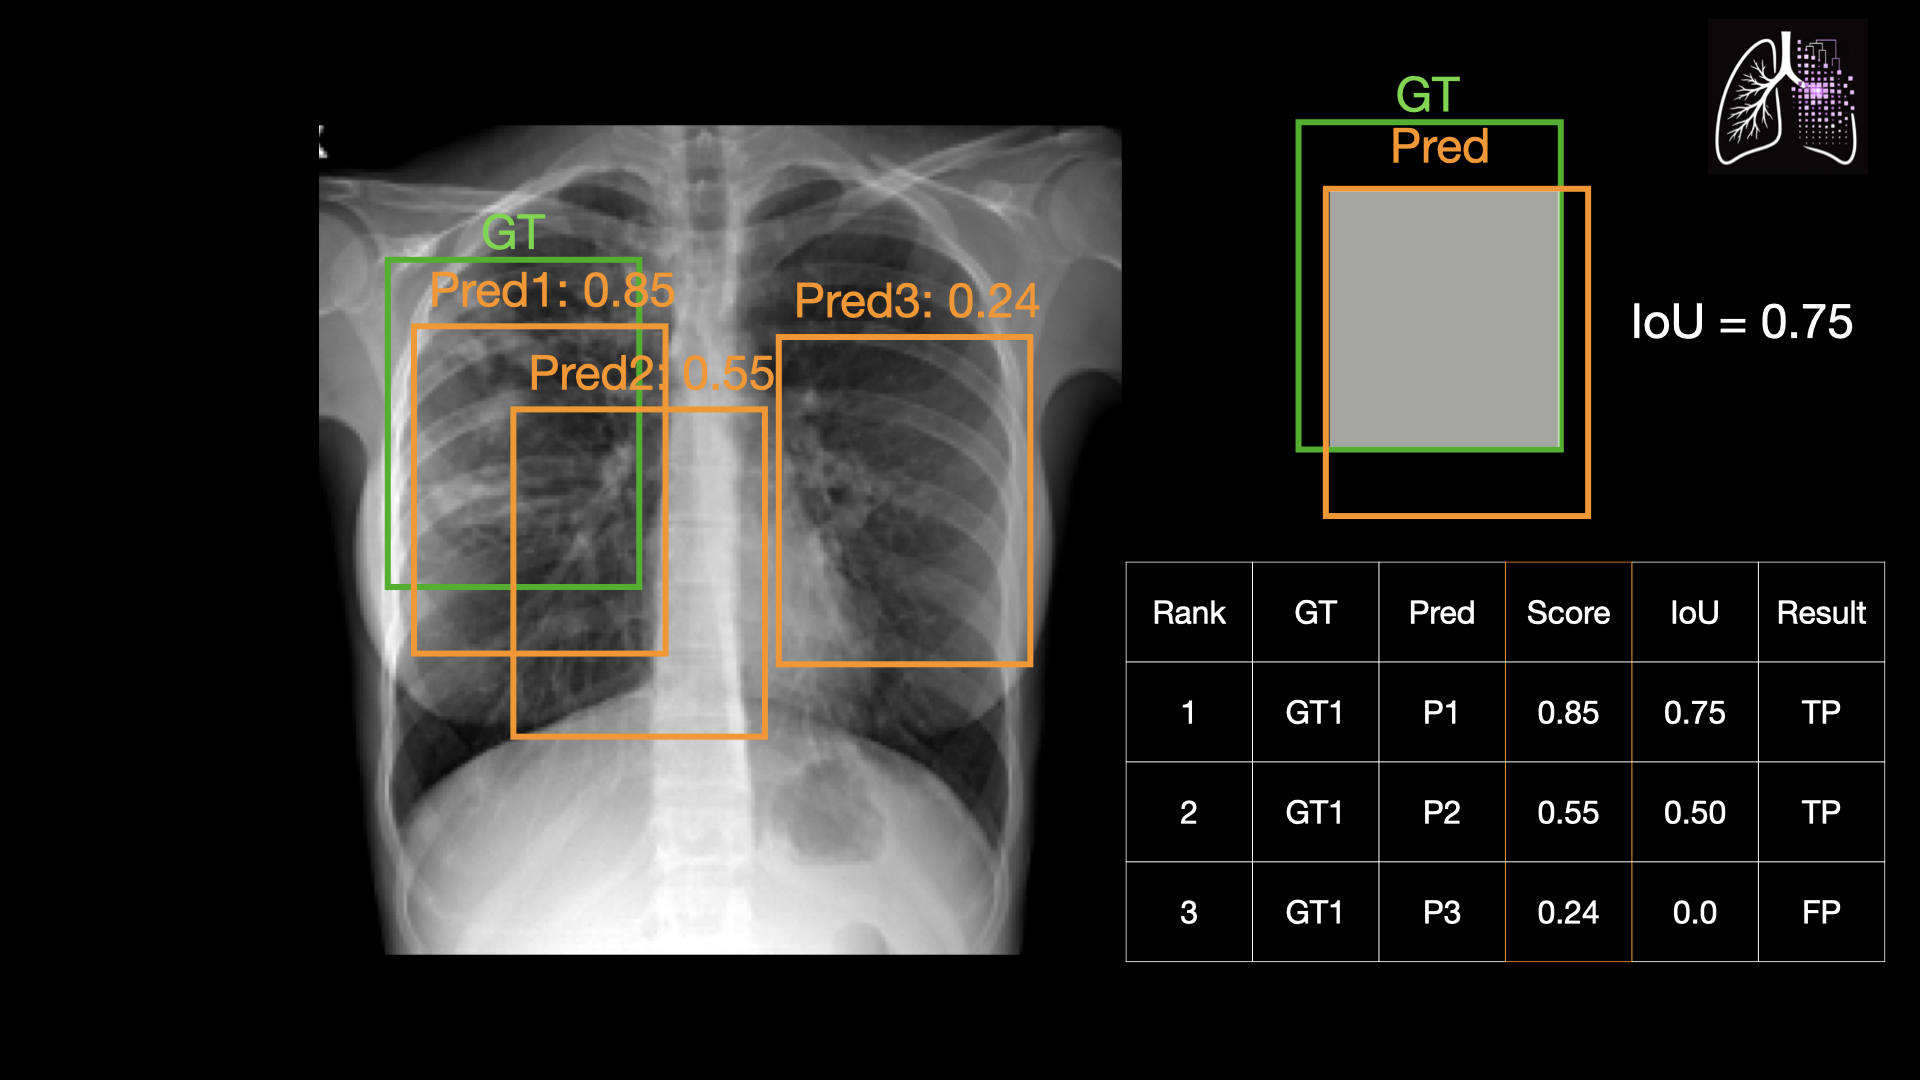

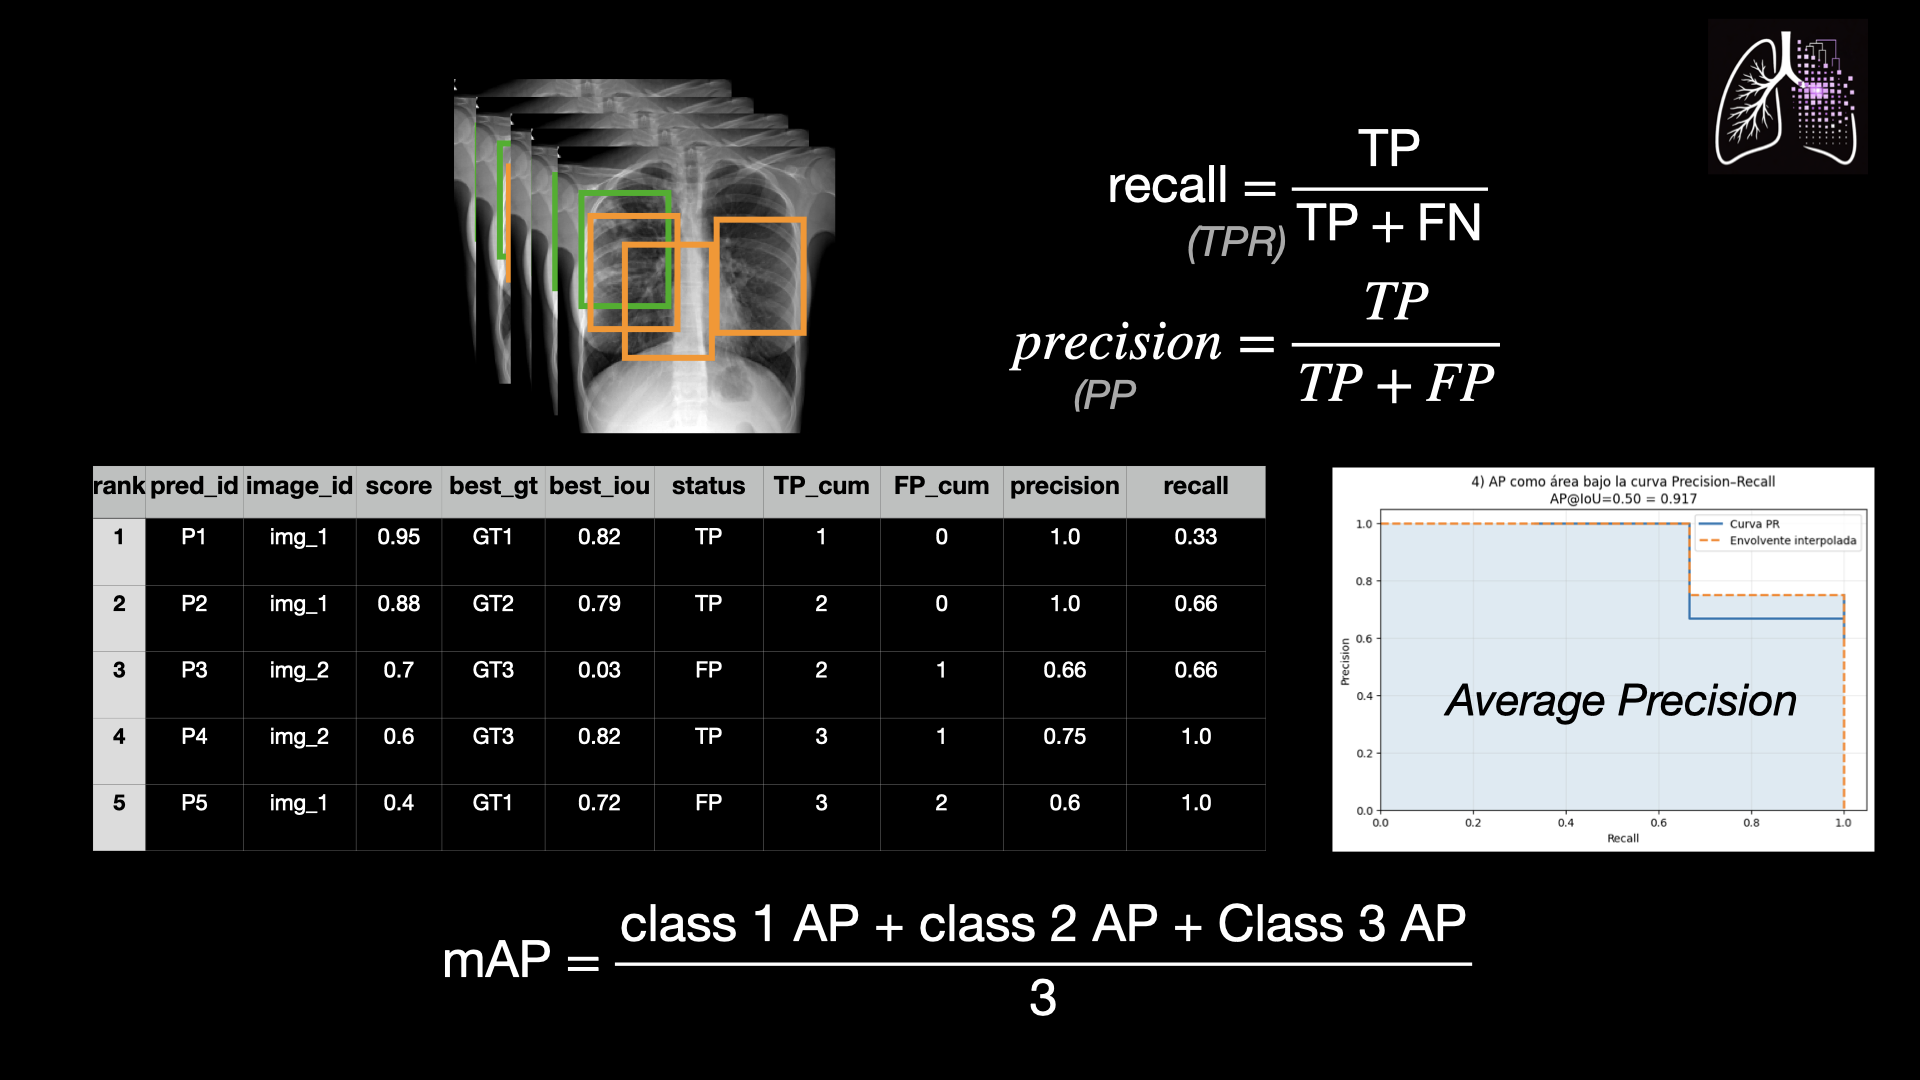

In [ ]:

# Bounding Boxes Format:
# [x_min, y_min, x_max, y_max]

def compute_iou(box_a, box_b):
    xA = max(box_a[0], box_b[0])
    yA = max(box_a[1], box_b[1])
    xB = min(box_a[2], box_b[2])
    yB = min(box_a[3], box_b[3])

    intersection_width = max(0, xB - xA)
    intersection_height = max(0, yB - yA)
    intersection_area = intersection_width * intersection_height

    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])

    union_area = area_a + area_b - intersection_area

    if union_area == 0:
        return 0.0

    return intersection_area / union_area


# ------------------------------------------------------------
# Simular ground truth y predicciones
# ------------------------------------------------------------

ground_truth_boxes = {
    "image_001": [
        {"box": [50, 50, 150, 150], "class_id": 0},
        {"box": [250, 80, 360, 200], "class_id": 0}
    ],
    "image_002": [
        {"box": [100, 100, 220, 240], "class_id": 0}
    ],
    "image_003": [
        {"box": [300, 300, 420, 430], "class_id": 0}
    ],
    "image_004": [],
    "image_005": [
        {"box": [60, 250, 180, 370], "class_id": 0}
    ]
}


predicted_boxes = {
    "image_001": [
        {"box": [55, 55, 148, 152], "class_id": 0, "score": 0.95},   # buen match
        {"box": [240, 75, 355, 205], "class_id": 0, "score": 0.88},   # buen match
        {"box": [400, 400, 480, 480], "class_id": 0, "score": 0.40}   # falso positivo
    ],
    "image_002": [
        {"box": [110, 110, 210, 230], "class_id": 0, "score": 0.90},  # buen match
        {"box": [300, 300, 380, 390], "class_id": 0, "score": 0.55}   # falso positivo
    ],
    "image_003": [
        {"box": [100, 100, 180, 180], "class_id": 0, "score": 0.70}   # no coincide
    ],
    "image_004": [
        {"box": [50, 50, 150, 150], "class_id": 0, "score": 0.60}     # falso positivo, no hay lesión real
    ],
    "image_005": [
        {"box": [65, 255, 175, 365], "class_id": 0, "score": 0.93}    # buen match
    ]
}

In [ ]:
ground_truth_boxes

#### Bounding Boxes: Coordinates Formats

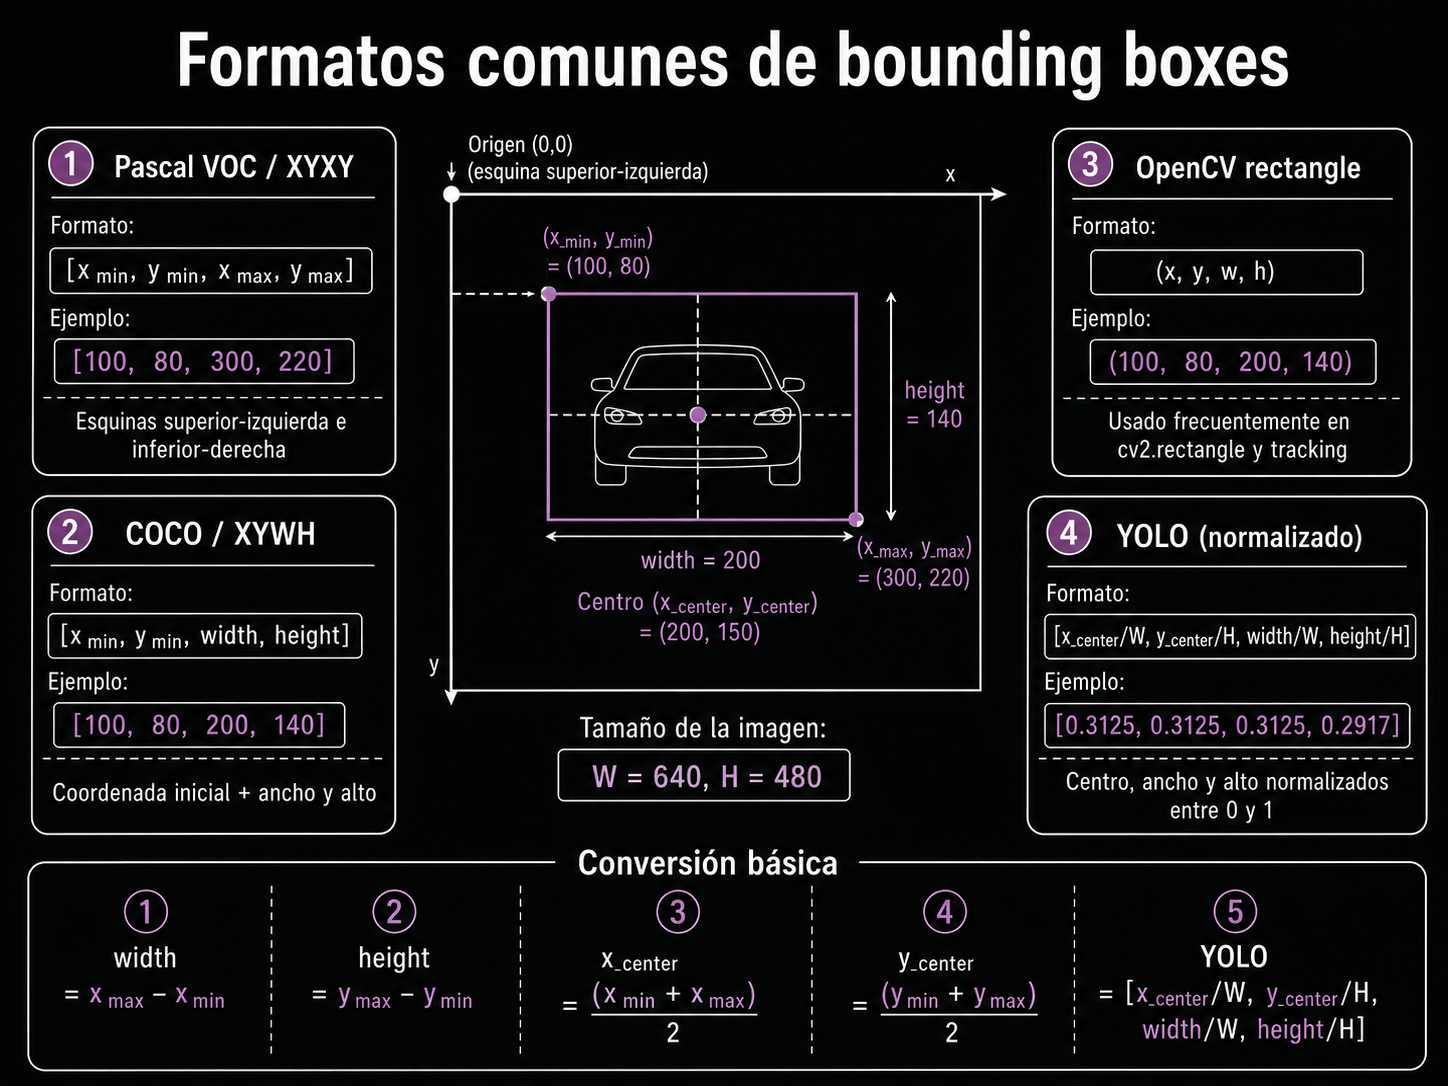

In [ ]:
### Evaluation

def evaluate_detection(
    ground_truth_boxes,
    predicted_boxes,
    iou_threshold=0.5,
    score_threshold=0.0,
    class_id=0
):
    results = []

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for image_id in ground_truth_boxes.keys():

        gt_boxes = [
            item for item in ground_truth_boxes[image_id]
            if item["class_id"] == class_id
        ]

        pred_boxes = [
            item for item in predicted_boxes.get(image_id, [])
            if item["class_id"] == class_id and item["score"] >= score_threshold
        ]

        # Ordenar predicciones por score descendente
        pred_boxes = sorted(pred_boxes, key=lambda x: x["score"], reverse=True)

        matched_gt_indices = set()

        image_tp = 0
        image_fp = 0

        for pred in pred_boxes:
            pred_box = pred["box"]

            best_iou = 0
            best_gt_index = None

            for gt_index, gt in enumerate(gt_boxes):
                if gt_index in matched_gt_indices:
                    continue

                iou = compute_iou(pred_box, gt["box"])

                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = gt_index

            if best_iou >= iou_threshold:
                image_tp += 1
                matched_gt_indices.add(best_gt_index)

                detection_status = "TP"
            else:
                image_fp += 1
                detection_status = "FP"

            results.append({
                "image_id": image_id,
                "score": pred["score"],
                "pred_box": pred_box,
                "best_iou": best_iou,
                "status": detection_status
            })

        image_fn = len(gt_boxes) - len(matched_gt_indices)

        total_tp += image_tp
        total_fp += image_fp
        total_fn += image_fn

    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    summary = {
        "IoU threshold": iou_threshold,
        "Score threshold": score_threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

    return pd.DataFrame(results), pd.DataFrame(summary, index=["value"]).T

In [ ]:
# Visualization

def plot_detection_example(
    image_id,
    ground_truth_boxes,
    predicted_boxes,
    image_size=(512, 512),
    score_threshold=0.0
):
    fig, ax = plt.subplots(figsize=(6, 6))

    ax.set_xlim(0, image_size[0])
    ax.set_ylim(image_size[1], 0)
    ax.set_title(f"Ejemplo de detección: {image_id}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    # Dibujar cajas reales
    for gt in ground_truth_boxes.get(image_id, []):
        x_min, y_min, x_max, y_max = gt["box"]

        rect = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            linewidth=2,
            label="Ground truth",
            color='green'
        )

        ax.add_patch(rect)
        ax.text(
            x_min,
            y_min - 5,
            "GT",
            fontsize=10,
            color='green'
        )

    # Dibujar cajas predichas
    for pred in predicted_boxes.get(image_id, []):
        if pred["score"] < score_threshold:
            continue

        x_min, y_min, x_max, y_max = pred["box"]

        rect = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            linestyle="--",
            linewidth=2,
            label="Predicción",
            color='darkorchid'
        )

        ax.add_patch(rect)
        ax.text(
            x_min,
            y_max + 15,
            f"Pred {pred['score']:.2f}",
            fontsize=10,
            color='darkorchid'
        )

    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_detection_example(
    image_id="image_001",
    ground_truth_boxes=ground_truth_boxes,
    predicted_boxes=predicted_boxes,
    image_size=(512, 512),
    score_threshold=0.0
)

In [ ]:
detection_results, detection_summary = evaluate_detection(
    ground_truth_boxes=ground_truth_boxes,
    predicted_boxes=predicted_boxes,
    iou_threshold=0.5,
    score_threshold=0.0,
    class_id=0
)

print("Resultados por predicción")
display(detection_results)

print("\nResumen de métricas de detección")
display(detection_summary)